# 11 — Monte Carlo Uncertainty Quantification and Final Evaluation

## Objective

The previous notebooks investigated several methods for analyzing and learning the MEMS system dynamics, including:

- signal processing,
- classical system identification,
- sparse equation discovery,
- symbolic regression,
- statistical and black-box machine learning,
- probabilistic machine learning,
- physics-informed machine learning,
- causal machine learning.

This final notebook returns to the central topic of the project:

> How can Monte Carlo simulation be used to quantify uncertainty in the physical system and in the resulting engineering quantities of interest?

The analysis uses the 1000 Monte Carlo realizations generated earlier and focuses on the propagation of uncertain physical and measurement parameters into system-level outputs.

The main objectives are to:

- quantify distributions of important outputs,
- estimate confidence intervals,
- identify which uncertain inputs are most strongly associated with output variability,
- compare output uncertainty across selected quantities,
- summarize how the different analysis methods contribute to uncertainty-aware system understanding.

In [1]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


PROJECT_ROOT = Path.cwd().parent


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

In [2]:
# LOAD MONTE CARLO RESULTS

monte_carlo_results_path = (
    data_path("monte_carlo")
    / "monte_carlo_results.csv"
)

monte_carlo_results = pd.read_csv(
    monte_carlo_results_path
)


print(
    f"Monte Carlo table shape: "
    f"{monte_carlo_results.shape}"
)

print()

print(
    "Selected uncertainty outputs:"
)

selected_outputs = [
    "natural_frequency",
    "damping_ratio",
    "peak_displacement",
    "peak_acceleration",
    "rms_acceleration",
    "peak_measured_signal",
    "rms_measured_signal",
]

for output_name in selected_outputs:
    print(
        f"- {output_name}"
    )

Monte Carlo table shape: (1000, 17)

Selected uncertainty outputs:
- natural_frequency
- damping_ratio
- peak_displacement
- peak_acceleration
- rms_acceleration
- peak_measured_signal
- rms_measured_signal


In [4]:
# CALCULATE MONTE CARLO UNCERTAINTY SUMMARY

import importlib
import src.uncertainty

importlib.reload(
    src.uncertainty
)


from src.uncertainty import (
    calculate_uncertainty_summary,
)


uncertainty_summary = (
    calculate_uncertainty_summary(
        data=monte_carlo_results,
        columns=selected_outputs,
        lower_percentile=2.5,
        upper_percentile=97.5,
    )
)


uncertainty_summary

,output,mean,standard_deviation,coefficient_of_variation_percent,minimum,lower_95_percentile,upper_95_percentile,maximum
0,natural_frequency,5.035831,0.148739,2.953615,4.537185,4.734841,5.327225,5.446955
1,damping_ratio,0.001263,0.000129,10.194125,0.000852,0.001022,0.001509,0.001674
2,peak_displacement,0.005501,0.000178,3.234547,0.005031,0.005217,0.005936,0.006389
3,peak_acceleration,6.446664,0.359790,5.581022,5.694898,5.914514,7.238243,7.636756
4,rms_acceleration,3.097808,0.134691,4.347938,2.734651,2.873074,3.391088,3.577856
5,peak_measured_signal,6.496102,0.365128,5.620729,5.604333,5.931620,7.296330,7.687021
6,rms_measured_signal,3.097579,0.138497,4.471123,2.661695,2.857754,3.397958,3.584805


## Monte Carlo Output Uncertainty

The 1000 Monte Carlo realizations produce uncertainty distributions for the main physical and measurement outputs.

The relative uncertainty can be compared using the coefficient of variation,

$$
CV
=
\frac{\sigma}{|\mu|}
\times 100\%.
$$

Among the selected outputs, the damping ratio exhibits the largest relative uncertainty:

$$
CV_{\zeta}
\approx
10.19\%.
$$

The natural frequency is comparatively stable, with

$$
CV_{f_n}
\approx
2.95\%.
$$

The dynamical response quantities show intermediate levels of uncertainty. The coefficients of variation are approximately

$$
3.23\%
$$

for peak displacement,

$$
4.35\%
$$

for RMS acceleration, and

$$
5.58\%
$$

for peak acceleration.

The measured-signal quantities exhibit slightly greater uncertainty than the corresponding true acceleration quantities. In particular, the coefficient of variation increases from approximately

$$
5.58\%
$$

for peak acceleration to

$$
5.62\%
$$

for peak measured signal, while the RMS coefficient of variation increases from approximately

$$
4.35\%
$$

to

$$
4.47\%.
$$

This is consistent with the Monte Carlo model because the measured signal contains additional uncertainty from sensor gain, bias, and measurement noise.

The empirical 95% intervals quantify the range containing the central 95% of the simulated outcomes under the assumed parameter distributions. These intervals describe output uncertainty and should not be interpreted as confidence intervals for the estimated mean.

In [5]:
# DEFINE UNCERTAIN INPUT PARAMETERS

uncertain_inputs = [
    "mass",
    "damping",
    "stiffness",
    "nonlinear_stiffness",
    "temperature",
    "noise_standard_deviation",
    "sensor_gain",
    "sensor_bias",
]


print(
    "Uncertain inputs used for sensitivity analysis:"
)

for input_name in uncertain_inputs:
    print(
        f"- {input_name}"
    )

Uncertain inputs used for sensitivity analysis:
- mass
- damping
- stiffness
- nonlinear_stiffness
- temperature
- noise_standard_deviation
- sensor_gain
- sensor_bias


In [12]:
# SPEARMAN RANK-CORRELATION SENSITIVITY ANALYSIS

import importlib
import src.uncertainty

importlib.reload(
    src.uncertainty
)


from src.uncertainty import (
    calculate_spearman_sensitivity,
)


spearman_sensitivity = (
    calculate_spearman_sensitivity(
        data=monte_carlo_results,
        input_columns=uncertain_inputs,
        output_columns=selected_outputs,
    )
)


spearman_sensitivity

,natural_frequency,damping_ratio,peak_displacement,peak_acceleration,rms_acceleration,peak_measured_signal,rms_measured_signal
mass,-0.497555,-0.161205,-0.591263,-0.832605,-0.909224,-0.817380,-0.887164
damping,0.017909,0.949993,-0.021794,0.005045,-0.042849,0.006508,-0.034950
stiffness,0.837920,-0.234148,-0.698661,0.468321,0.361642,0.455533,0.346900
nonlinear_stiffness,-0.008844,0.011462,-0.020800,-0.014911,-0.022755,-0.009816,-0.015843
temperature,-0.017569,-0.007300,-0.012974,-0.024824,-0.018020,-0.033283,-0.033134
noise_standard_deviation,-0.023273,-0.048525,-0.007771,-0.021658,-0.012885,0.060253,-0.011899
sensor_gain,0.000281,0.028021,0.017951,0.011922,0.026684,0.179443,0.234904
sensor_bias,-0.026251,0.065957,0.025268,-0.012232,-0.009984,-0.002773,-0.002678


## Rank-Correlation Sensitivity Analysis

Spearman rank correlation was used as a global screening measure to examine monotonic relationships between uncertain input parameters and the selected Monte Carlo outputs.

The analysis reveals physically meaningful parameter–response relationships.

### Natural Frequency

Natural frequency is most strongly associated with stiffness,

$$
\rho_s(k,f_n)
=
0.838,
$$

while mass has a substantial negative association,

$$
\rho_s(m,f_n)
=
-0.498.
$$

This is consistent with the physical relationship

$$
f_n
\propto
\sqrt{\frac{k}{m}},
$$

according to which increasing stiffness raises natural frequency while increasing mass lowers it.

### Damping Ratio

The damping ratio is dominated by the damping coefficient,

$$
\rho_s(c,\zeta)
=
0.950.
$$

This is the strongest input–output association in the sensitivity matrix and is consistent with the analytical dependence of damping ratio on the damping coefficient.

### Displacement and Acceleration

Peak displacement is most strongly associated with stiffness and mass, with correlations of approximately

$$
-0.699
$$

and

$$
-0.591,
$$

respectively.

Acceleration-related outputs are particularly sensitive to mass. The Spearman correlation between mass and RMS acceleration reaches approximately

$$
-0.909.
$$

Stiffness provides a secondary positive influence on acceleration quantities.

### Measurement Uncertainty

The measured-signal outputs preserve the dominant physical effects of mass and stiffness, but sensor gain also becomes visible.

For RMS measured signal,

$$
\rho_s(\mathrm{sensor\ gain},y_{\mathrm{RMS}})
\approx
0.235.
$$

This demonstrates how measurement-system uncertainty can add an additional source of variability on top of the underlying physical uncertainty.

### Variables with Weak Associations

Temperature exhibits correlations close to zero for all investigated outputs. This is expected because temperature was sampled as an uncertain variable but was not coupled to the governing dynamical equations in the present model.

The nonlinear-stiffness parameter also exhibits weak rank correlations within the investigated parameter range and excitation conditions. This indicates that it does not produce a strong monotonic influence on the selected summary outputs in this particular Monte Carlo experiment.

These results should be interpreted as rank-correlation sensitivity indicators rather than causal effects or variance-based sensitivity indices.

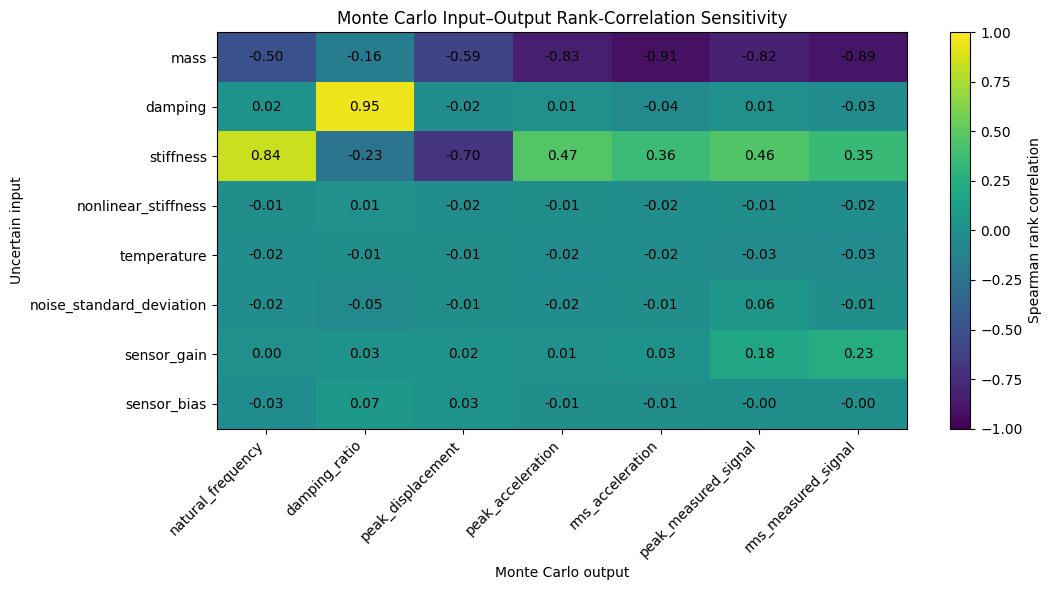

In [13]:
# VISUALIZE SPEARMAN SENSITIVITY MATRIX

fig, ax = plt.subplots(
    figsize=(11, 6)
)


image = ax.imshow(
    spearman_sensitivity.to_numpy(),
    aspect="auto",
    vmin=-1.0,
    vmax=1.0,
)


# Input names on the vertical axis.
ax.set_yticks(
    np.arange(
        len(spearman_sensitivity.index)
    )
)

ax.set_yticklabels(
    spearman_sensitivity.index
)


# Output names on the horizontal axis.
ax.set_xticks(
    np.arange(
        len(spearman_sensitivity.columns)
    )
)

ax.set_xticklabels(
    spearman_sensitivity.columns,
    rotation=45,
    ha="right",
)


# Add the numerical correlation value to every cell.
for row_index in range(
    spearman_sensitivity.shape[0]
):

    for column_index in range(
        spearman_sensitivity.shape[1]
    ):

        value = spearman_sensitivity.iloc[
            row_index,
            column_index,
        ]

        ax.text(
            column_index,
            row_index,
            f"{value:.2f}",
            ha="center",
            va="center",
        )


colorbar = fig.colorbar(
    image,
    ax=ax,
)

colorbar.set_label(
    "Spearman rank correlation"
)


ax.set_title(
    "Monte Carlo Input–Output Rank-Correlation Sensitivity"
)

ax.set_xlabel(
    "Monte Carlo output"
)

ax.set_ylabel(
    "Uncertain input"
)


plt.tight_layout()

plt.show()

In [14]:
# SAVE SPEARMAN SENSITIVITY FIGURE

uncertainty_figure_directory = figures_path(
    "uncertainty"
)

ensure_directory(
    uncertainty_figure_directory
)


spearman_sensitivity_figure_path = (
    uncertainty_figure_directory
    / "spearman_sensitivity_matrix.png"
)


fig.savefig(
    spearman_sensitivity_figure_path,
    dpi=300,
    bbox_inches="tight",
)


print(
    "Spearman sensitivity figure saved to:"
)

print(
    spearman_sensitivity_figure_path
)

Spearman sensitivity figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\uncertainty\spearman_sensitivity_matrix.png


In [15]:
# SAVE MONTE CARLO UQ RESULT TABLES

monte_carlo_uq_results_directory = results_path(
    "monte_carlo_uq"
)

ensure_directory(
    monte_carlo_uq_results_directory
)


# Save uncertainty summary.
uncertainty_summary_path = (
    monte_carlo_uq_results_directory
    / "output_uncertainty_summary.csv"
)

uncertainty_summary.to_csv(
    uncertainty_summary_path,
    index=False,
)


# Save Spearman sensitivity matrix.
spearman_sensitivity_path = (
    monte_carlo_uq_results_directory
    / "spearman_sensitivity_matrix.csv"
)

spearman_sensitivity.to_csv(
    spearman_sensitivity_path,
)


print(
    "Uncertainty summary saved to:"
)

print(
    uncertainty_summary_path
)

print()

print(
    "Spearman sensitivity matrix saved to:"
)

print(
    spearman_sensitivity_path
)

Uncertainty summary saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\monte_carlo_uq\output_uncertainty_summary.csv

Spearman sensitivity matrix saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\monte_carlo_uq\spearman_sensitivity_matrix.csv


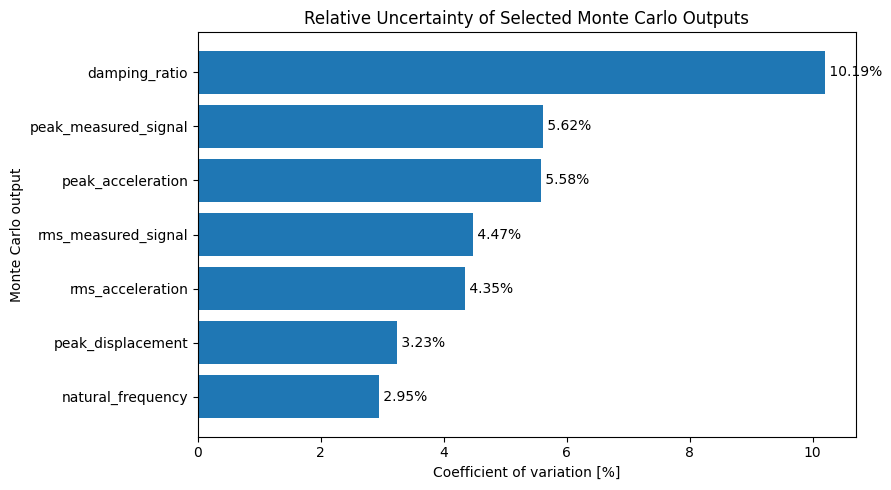

Coefficient-of-variation figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\uncertainty\output_coefficient_of_variation.png


In [16]:
# COMPARE RELATIVE OUTPUT UNCERTAINTY

# Sort outputs from lowest to highest relative uncertainty.
cv_comparison = uncertainty_summary[
    [
        "output",
        "coefficient_of_variation_percent",
    ]
].sort_values(
    by="coefficient_of_variation_percent",
    ascending=True,
)


# Create the figure.
fig_cv, ax_cv = plt.subplots(
    figsize=(9, 5)
)


ax_cv.barh(
    cv_comparison["output"],
    cv_comparison[
        "coefficient_of_variation_percent"
    ],
)


ax_cv.set_xlabel(
    "Coefficient of variation [%]"
)

ax_cv.set_ylabel(
    "Monte Carlo output"
)

ax_cv.set_title(
    "Relative Uncertainty of Selected Monte Carlo Outputs"
)


# Add the numerical CV value next to each bar.
for bar, value in zip(
    ax_cv.patches,
    cv_comparison[
        "coefficient_of_variation_percent"
    ],
):

    ax_cv.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f" {value:.2f}%",
        va="center",
    )


plt.tight_layout()



# SAVE THIS SAME FIGURE

cv_figure_path = (
    uncertainty_figure_directory
    / "output_coefficient_of_variation.png"
)


fig_cv.savefig(
    cv_figure_path,
    dpi=300,
    bbox_inches="tight",
)


plt.show()


print(
    "Coefficient-of-variation figure saved to:"
)

print(
    cv_figure_path
)

## Relative Output Uncertainty

The coefficient of variation provides a dimensionless comparison of uncertainty across outputs with different physical units and magnitudes.

The damping ratio exhibits the largest relative uncertainty,

$$
CV \approx 10.19\%.
$$

This is substantially larger than the remaining outputs.

Peak acceleration and peak measured signal show intermediate relative uncertainty of approximately

$$
5.58\%
$$

and

$$
5.62\%,
$$

respectively.

The RMS acceleration and RMS measured signal have coefficients of variation of approximately

$$
4.35\%
$$

and

$$
4.47\%.
$$

Peak displacement has a lower relative uncertainty of approximately

$$
3.23\%,
$$

while natural frequency is the most stable of the investigated outputs, with

$$
CV \approx 2.95\%.
$$

The slightly larger uncertainty of the measured-signal quantities compared with the corresponding physical acceleration quantities is consistent with the additional gain, bias, and noise uncertainty introduced by the sensor model.

In [17]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 11

notebook_11_outputs = {
    "output_uncertainty_summary":
        uncertainty_summary_path,

    "spearman_sensitivity_matrix":
        spearman_sensitivity_path,

    "spearman_sensitivity_figure":
        spearman_sensitivity_figure_path,

    "coefficient_of_variation_figure":
        cv_figure_path,
}


for output_name, output_path in notebook_11_outputs.items():

    print(
        f"{output_name:40s} "
        f"{output_path.exists()}"
    )

output_uncertainty_summary               True
spearman_sensitivity_matrix              True
spearman_sensitivity_figure              True
coefficient_of_variation_figure          True


# Notebook 11 Summary

This notebook completed the Monte Carlo uncertainty-quantification analysis by evaluating how uncertain physical and measurement parameters propagate into important MEMS system outputs.

A total of 1000 Monte Carlo realizations were analyzed.

## Output Uncertainty

The empirical output distributions were summarized using the mean, standard deviation, coefficient of variation, minimum, maximum, and central 95% Monte Carlo uncertainty interval.

Among the investigated outputs, the damping ratio exhibited the largest relative uncertainty:

$$
CV_{\zeta}
\approx
10.19\%.
$$

Natural frequency was the most stable selected output:

$$
CV_{f_n}
\approx
2.95\%.
$$

The main dynamical response quantities showed intermediate levels of uncertainty. Peak acceleration had a coefficient of variation of approximately

$$
5.58\%,
$$

while RMS acceleration had

$$
4.35\%.
$$

The corresponding measured-signal quantities showed slightly larger relative uncertainty because the sensor model introduced additional uncertainty through gain, bias, and measurement noise.

## Rank-Correlation Sensitivity

Spearman rank correlation was used as a global screening measure for monotonic input-output relationships.

Natural frequency was dominated by stiffness,

$$
\rho_s(k,f_n)
\approx
0.838,
$$

with mass providing an opposing influence,

$$
\rho_s(m,f_n)
\approx
-0.498.
$$

This agrees with the physical dependence

$$
f_n
\propto
\sqrt{\frac{k}{m}}.
$$

The damping ratio was dominated by the damping coefficient:

$$
\rho_s(c,\zeta)
\approx
0.950.
$$

Acceleration-related quantities were particularly sensitive to mass. For example,

$$
\rho_s(m,a_{\mathrm{RMS}})
\approx
-0.909.
$$

Stiffness provided a secondary positive influence on acceleration quantities.

For the measured-signal outputs, sensor gain introduced additional sensitivity. The correlation between sensor gain and RMS measured signal was approximately

$$
0.235.
$$

Temperature remained essentially uncorrelated with the selected outputs, which is consistent with the fact that temperature was sampled as an uncertain parameter but was not coupled to the governing dynamics in the present model.

The nonlinear-stiffness parameter also showed weak monotonic associations under the investigated parameter range and excitation conditions.

## Overall Uncertainty Interpretation

The Monte Carlo analysis demonstrates that different engineering quantities respond differently to the same underlying parameter uncertainty.

Some outputs, such as natural frequency, remain comparatively stable, whereas others, such as damping ratio, are considerably more sensitive to parameter variation.

The sensitivity analysis also separates physical uncertainty from measurement-system uncertainty. Physical quantities are mainly controlled by mass, stiffness, and damping, while sensor gain contributes additional uncertainty to measured signals.

## Final Project Perspective

Across the project, Monte Carlo simulation provides the common uncertainty framework connecting the different analysis approaches.

Signal processing characterized the dynamic response in the frequency domain.

Classical system identification estimated physical model parameters.

Sparse equation discovery and symbolic regression investigated recovery of governing relationships from data.

Statistical, black-box, probabilistic, and physics-informed machine-learning methods examined different ways of predicting system dynamics.

Causal machine learning investigated intervention-based physical relationships.

The final Monte Carlo uncertainty analysis places these methods within an uncertainty-aware engineering context by quantifying the variability of the system and identifying the parameters most strongly associated with important outputs.

The project therefore demonstrates how Monte Carlo simulation, physical modeling, signal processing, system identification, machine learning, equation discovery, probabilistic modeling, physics-informed learning, and causal analysis can be integrated into a unified information-engineering workflow for uncertain dynamical systems.